In [116]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import TunedThresholdClassifierCV

from sklearn.metrics import (
    make_scorer,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

In [117]:
import sklearn
# 1. Enable metadata routing globally
sklearn.set_config(enable_metadata_routing=True)

In [ ]:
# Load dataset
all_matches = pd.read_csv("dataset/extracted/combined_player_stats_new.csv")

# Features used for training
features = [
    "kills_per_round",
    "deaths_per_round",
    "kd_ratio",
    "headshot_rate",
    "has_kills",
    "avg_speed",
    "avg_accuracy_penalty",
    "damage_per_round", 
    # "damagepr_and_headshotrate_interaction",
    # "smoke_kill_ratio",	
    # "blind_kill_ratio",
    "air_kill_ratio"
]

X = all_matches[features].replace([np.inf, -np.inf], np.nan)
y = all_matches["is_cheater"]
groups = all_matches["match_id"]

In [119]:
all_matches[all_matches["blind_kill_ratio"]>0]['is_cheater'].sum()

np.int64(50)

In [120]:
# Split by match to prevent data leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training records: 1400
Testing records: 360

Training class distribution:
is_cheater
0    1108
1     292
Name: count, dtype: int64

Testing class distribution:
is_cheater
0    286
1     74
Name: count, dtype: int64


In [121]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [122]:
# Model Definitions
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            random_state=42
        ))
    ]),

    "XGBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42
        ))
    ])
}

In [123]:
# Tuned Models
tuned_models = {
    "Logistic Regression": TunedThresholdClassifierCV(
        estimator=models["Logistic Regression"],
        scoring=make_scorer(f1_score, zero_division=0),
        cv=cv
    ),

    "Random Forest": TunedThresholdClassifierCV(
        estimator=models["Random Forest"],
        scoring=make_scorer(f1_score, zero_division=0),
        cv=cv
        ),

    "XGBoost": TunedThresholdClassifierCV(
        estimator=models["XGBoost"],
        scoring=make_scorer(f1_score, zero_division=0),
        cv=cv
        ),
}

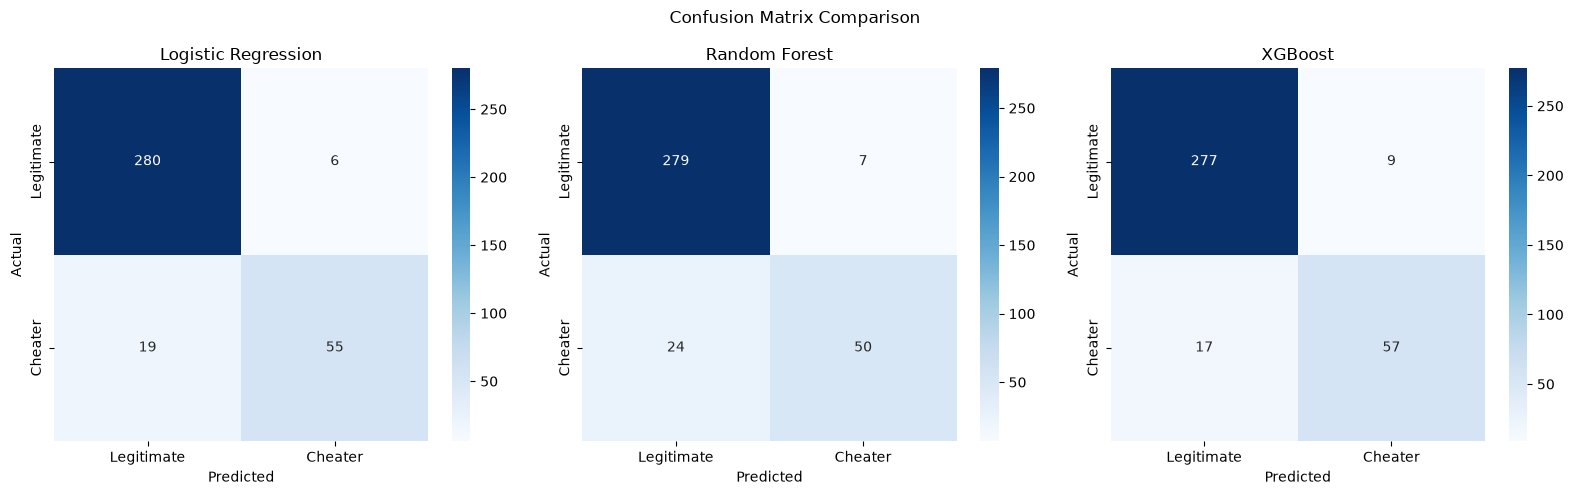

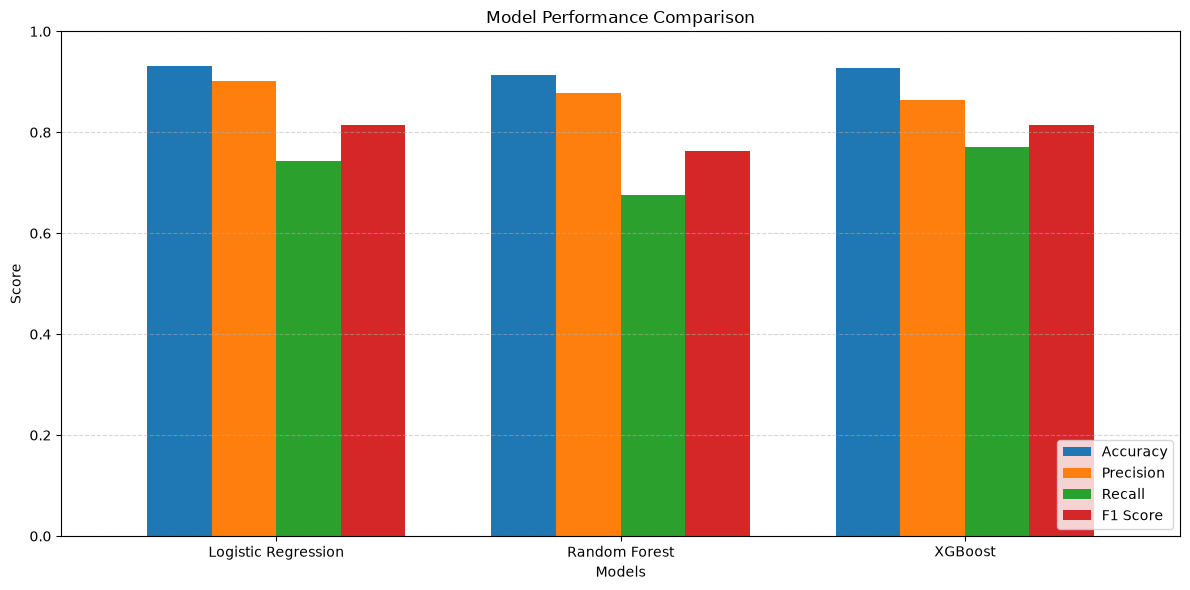

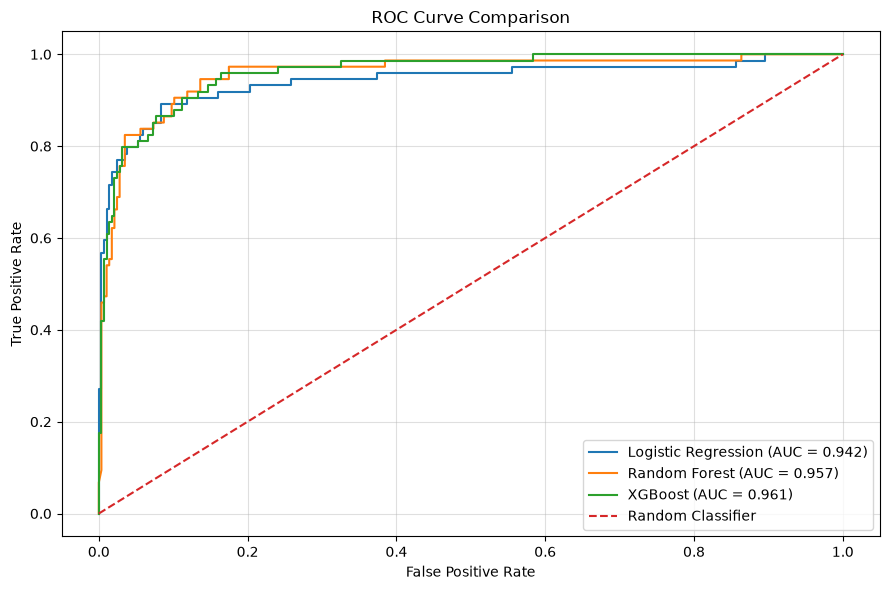

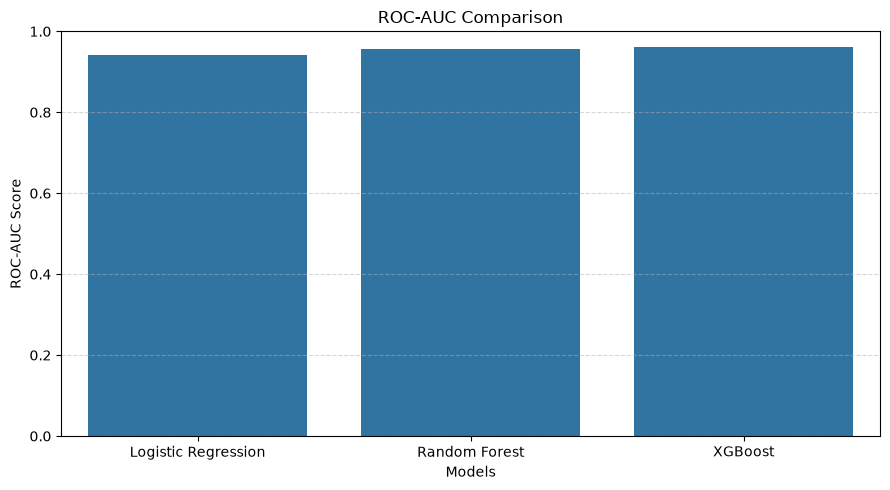


FINAL MODEL COMPARISON

              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.9306     0.9016  0.7432    0.8148   0.9423
      Random Forest    0.9139     0.8772  0.6757    0.7634   0.9569
            XGBoost    0.9278     0.8636  0.7703    0.8143   0.9606


In [124]:

# Store evaluation results
results = []

# Store predictions and probabilities
predictions = {}

curr_models = tuned_models

# Train and evaluate models
for name, model in curr_models.items():
    
    if curr_models == tuned_models:
        model.fit(X_train, y_train, groups=groups_train)
    else: 
        model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = {
        "y_pred": y_pred,
        "y_prob": y_prob
    }

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

# ------------------------------------------------
# 1. CONFUSION MATRICES
# ------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, model) in zip(axes, curr_models.items()):

    y_pred = predictions[name]["y_pred"]

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Cheater"],
        yticklabels=["Legitimate", "Cheater"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Confusion Matrix Comparison")
plt.tight_layout()
plt.show()


# ------------------------------------------------
# 2. ACCURACY, PRECISION, RECALL AND F1 COMPARISON
# ------------------------------------------------

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.75
)

plt.title("Model Performance Comparison")
plt.xlabel("Models")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# 3. ROC CURVES
# ------------------------------------------------

plt.figure(figsize=(9, 6))

for name in curr_models:

    y_prob = predictions[name]["y_prob"]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# 4. ROC-AUC COMPARISON
# ------------------------------------------------

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="ROC-AUC"
)

plt.ylim(0, 1)
plt.title("ROC-AUC Comparison")
plt.xlabel("Models")
plt.ylabel("ROC-AUC Score")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# 5. PRINT FINAL RESULTS
# ------------------------------------------------

print("\nFINAL MODEL COMPARISON\n")

print(
    results_df.round(4).to_string(index=False)
)


In [125]:
# Saving Models
import joblib

for name, model in tuned_models.items():
    filename = "models/v2/" + name.lower().replace(" ", "_") + ".pkl"
    joblib.dump(model, filename)

print("Models saved successfully!")

Models saved successfully!
